# Trabalho Integrador – Aquisição e Preparação de Dados
## Pix e TED: do dado bruto à tabela estruturada

**Aluno:** Vinicius Galoa Fonseca Santos  |  **RA:** 2026110561  |  **Professor:** Prof. Me. Heron Bussolim Barbosa

**Como usar:** `Ambiente de execução > Executar tudo`. O notebook baixa os dados do Banco Central por código (sem planilhas), trata, integra e gera o gráfico e o CSV final.

**Importante:** as células marcadas com ⚠️ exigem que **você confira o resultado na tela** (nomes de colunas, unidades). Entenda cada bloco antes de entregar: o professor pode arguir qualquer etapa.

## Etapa 0 – Configuração e funções auxiliares

In [40]:
import json, re, hashlib, unicodedata, zipfile, gzip, time
from datetime import datetime
from pathlib import Path
from zoneinfo import ZoneInfo

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", 80)
PIX_MES_PARADA = "202611"   # o download para ao chegar neste mês, sem baixá-lo (AAAAMM)

# Pastas de trabalho (no Colab, /content)
BASE_DIR = Path("/content") if Path("/content").exists() else Path(".")
RAW_DIR = BASE_DIR / "raw"        # dados brutos exatamente como recebidos
OUT_DIR = BASE_DIR / "saidas"     # tabela final, gráfico, evidências
RAW_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Data/hora da coleta (fuso de Brasília) – ajustada para limitar até Novembro de 2026
TZ = ZoneInfo("America/Sao_Paulo")
AGORA = datetime(2026, 11, 13, tzinfo=TZ)
DATA_COLETA = AGORA.strftime("%Y-%m-%d %H:%M:%S %Z")
CARIMBO = AGORA.strftime("%Y%m%d_%H%M%S")

# Endpoints da API Olinda do Banco Central
URL_PIX = "https://olinda.bcb.gov.br/olinda/servico/Pix_DadosAbertos/versao/v1/odata/EstatisticasTransacoesPix"
URL_TED = "https://olinda.bcb.gov.br/olinda/servico/MPV_DadosAbertos/versao/v1/odata/MeiosdePagamentosMensalDA"

# ⚠️ Só altere se a detecção automática (Etapa 3) escolher a coluna errada. None = detectar sozinho.
CFG = {
    "pix": {"mes": None, "qtd": None, "valor": None},
    "ted": {"mes": None, "qtd": None, "valor": None,
            "col_instrumento": None, "valores_instrumento": None},
}

PIX_SO_COLUNAS_ESSENCIAIS = False
PIX_MES_INICIAL = "2020-11"      # lançamento do Pix

# ⚠️ Multiplicadores para levar cada variável da unidade ORIGINAL até a unidade-base
MULT_ORIGEM = {
    "pix": {"qtd": 1.0, "valor": 1.0},
    "ted": {"qtd": 1.0, "valor": 1.0},
}

In [41]:
# ----------------------------- funções auxiliares (usadas em todas as etapas)

def _get(url, timeout=90, tentativas=3):
    # A URL é montada À MÃO: o requests codifica "$" como "%24" quando se usa params=, e o Olinda rejeita (HTTP 400).
    ultimo = None
    for t in range(tentativas):
        try:
            r = requests.get(url, timeout=timeout)
            if r.status_code == 200:
                return r.json()
            ultimo = f"HTTP {r.status_code} em {url}\n{r.text[:600]}"
            if r.status_code < 500:      # erro do cliente (400/404): repetir não adianta
                break
        except requests.RequestException as e:
            ultimo = f"{type(e).__name__}: {e}"
        time.sleep(2 * (t + 1))
    raise RuntimeError(ultimo)


def baixar_odata(url_base, extra="", page=10000, max_paginas=500):
    # Baixa todos os registros de um recurso OData, paginando com $top/$skip.
    # url_base: endereço sem query. extra: parâmetros adicionais já formatados (ex.: "&@Database='202011'").
    registros, ultimo_hash, contexto = [], None, None
    for p in range(max_paginas):
        corpo = _get(f"{url_base}?$format=json&$top={page}&$skip={p * page}{extra}")
        contexto = corpo.get("@odata.context", contexto)
        lote = corpo.get("value", [])
        if not lote:
            break
        h = hashlib.md5(json.dumps(lote, sort_keys=True).encode()).hexdigest()
        if h == ultimo_hash:      # o servidor ignorou $skip e repetiu a página
            break
        ultimo_hash = h
        registros.extend(lote)
        if len(lote) < page:
            break
    return registros, contexto


def baixar_pix(select_cols=None):
    # EstatisticasTransacoesPix é uma FUNÇÃO OData: exige Database=@Database (AAAAMM). Um request por mês.
    meses = pd.period_range(PIX_MES_INICIAL, AGORA.strftime("%Y-%m"), freq="M")
    base = f"{URL_PIX}(Database=@Database)"
    tudo, ctx, falhas, select = [], None, [], ""
    for m in meses:
        ym = f"{m.year}{m.month:02d}"
        try:
            reg, c = baixar_odata(base, f"&@Database='{ym}'" + select)
        except RuntimeError as e:
            falhas.append((ym, str(e).splitlines()[0])); print(f"  Pix {ym}: FALHOU -> {falhas[-1][1]}"); continue
        ctx = ctx or c
        if reg and PIX_SO_COLUNAS_ESSENCIAIS and not select:
            cols = resolver_colunas(pd.json_normalize(reg[:200]), CFG["pix"], "PIX")
            chaves = [cols["mes"], cols["qtd"], cols["valor"]]
            select = "&$select=" + ",".join(chaves)
            reg = [{k: r.get(k) for k in chaves} for r in reg]     # primeiro mês já veio completo: reduz igual aos demais
        tudo.extend(reg)
        print(f"  Pix {ym}: {len(reg):>8,} linhas (acumulado: {len(tudo):,})")
    if not tudo:
        raise RuntimeError(f"Nenhum mês do Pix retornou dados. Primeiras falhas: {falhas[:3]}")
    if falhas:
        print(f"⚠️ {len(falhas)} mês(es) falharam: {[f[0] for f in falhas]} (aparecerão como lacunas no diagnóstico)")
    return tudo, ctx


def salvar_bruto(registros, contexto, chave):
    # Guarda o dado bruto (evidência do estado inicial), comprimido, com carimbo de data/hora.
    caminho = RAW_DIR / f"{chave}_bruto_{CARIMBO}.json.gz"
    with gzip.open(caminho, "wt", encoding="utf-8") as f:
        json.dump({"@odata.context": contexto, "value": registros}, f, ensure_ascii=False)
    return caminho


def carregar_bruto(caminho):
    with gzip.open(caminho, "rt", encoding="utf-8") as f:
        return json.load(f)["value"]


def ler_inicio_bruto(caminho, n=700):
    with gzip.open(caminho, "rt", encoding="utf-8") as f:
        return f.read(n)


def norm_nome(s):
    # "Quantidade de Transações" -> "quantidade_de_transacoes"
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode()
    return re.sub(r"[^0-9a-zA-Z]+", "_", s).strip("_").lower()


def parse_mes(s):
    # Converte AAAAMM, 'AAAA-MM', 'AAAA-MM-DD' ou datetime para o 1º dia do mês. Inválidos -> NaT.
    if pd.api.types.is_datetime64_any_dtype(s):
        return s.dt.to_period("M").dt.to_timestamp()
    txt = s.astype("string").str.strip().str.replace(r"\.0$", "", regex=True)
    out = pd.Series(pd.NaT, index=s.index, dtype="datetime64[ns]")
    m6 = txt.str.fullmatch(r"\d{6}").fillna(False).astype(bool)
    if m6.any():
        out[m6] = pd.to_datetime(txt[m6], format="%Y%m", errors="coerce")
    resto = (~m6 & txt.notna()).to_numpy()
    if resto.any():
        try:
            conv = pd.to_datetime(txt[resto], errors="coerce", format="mixed")
        except (ValueError, TypeError):
            conv = pd.to_datetime(txt[resto], errors="coerce")
        out[resto] = conv
    return out.dt.to_period("M").dt.to_timestamp()


def para_numero(s):
    # Converte para float; aceita texto com vírgula decimal. Não convertíveis -> NaN.
    if pd.api.types.is_numeric_dtype(s):
        return s.astype(float)
    t = s.astype("string").str.strip()
    if t.str.contains(",", regex=False).fillna(False).any():
        t = t.str.replace(".", "", regex=False).str.replace(",", ".", regex=False)
    return pd.to_numeric(t, errors="coerce")


def casas_dec(num):
    num = num.dropna()
    if num.empty:
        return 0
    dec = num.astype(str).str.extract(r"\.(\d+)$")[0].dropna()
    return int(dec.str.rstrip("0").str.len().max()) if len(dec) else 0


PADROES = {
    "mes":   r"(ano_?mes|^data|database|periodo|competencia|^mes)",
    "qtd":   r"(quant|qtd|qtde)",
    "valor": r"(^|_)(valor|vl|vlr|montante)",
}

def resolver_colunas(df, cfg, nome):
    out = {}
    for k, padrao in PADROES.items():
        if cfg.get(k):
            out[k] = cfg[k]
            print(f"[{nome}] {k:5s} -> '{out[k]}' (definida em CFG)")
            continue
        cands = [c for c in df.columns if re.search(padrao, norm_nome(c))]
        out[k] = cands[0] if cands else None
        aviso = f"  ⚠️ várias candidatas: {cands}" if len(cands) > 1 else ""
        print(f"[{nome}] {k:5s} -> {out[k]!r}{aviso}")
    faltando = [k for k, v in out.items() if v is None]
    if faltando:
        raise ValueError(f"[{nome}] Não achei coluna para {faltando}. Colunas disponíveis: {list(df.columns)}. Preencha CFG na Etapa 0.")
    return out

## Etapa 1 – Aquisição das bases

Duas fontes públicas do Banco Central do Brasil, ambas consumidas por **API OData (Olinda)** em JSON:

| Modalidade | Recurso | Conteúdo esperado |
|---|---|---|
| Pix | `Pix_DadosAbertos / EstatisticasTransacoesPix(Database=@Database)` | quantidade e valor de transações Pix liquidadas, por mês. **Função OData: uma requisição por mês (AAAAMM)** |
| TED | `MPV_DadosAbertos / MeiosdePagamentosMensalDA` (conjunto *Estatísticas de Meios de Pagamentos*) | operações com boletos e transferências de crédito (inclui TED), por mês |

Cada base é salva **bruta** (comprimida, `.json.gz`) em `raw/` antes de qualquer transformação. O download do Pix faz uma chamada por mês, então pode levar alguns minutos.

In [42]:
# ===== CORREÇÃO A: download do Pix mês a mês (sem estourar a RAM) =====
PIX_SO_COLUNAS_ESSENCIAIS = True
PIX_MES_PARADA = "202611"   # o download PARA (break) ao chegar neste mês, sem baixá-lo (AAAAMM)

def _get(url, timeout=180, tentativas=2):
    ultimo = None
    for t in range(tentativas):
        try:
            r = requests.get(url, timeout=timeout)
            if r.status_code == 200:
                return r.json()
            ultimo = f"HTTP {r.status_code} em {url}\n{r.text[:800]}"
            if r.status_code < 500:
                break
        except requests.RequestException as e:
            ultimo = f"{type(e).__name__}: {e}"
        time.sleep(3)
    raise RuntimeError(ultimo)


TOP_MAX = 1_000_000

def baixar_odata(url_base, extra="", page=10000, max_paginas=500, paginar=True):
    if paginar:
        registros, ultimo_hash, contexto = [], None, None
        try:
            for p in range(max_paginas):
                corpo = _get(f"{url_base}?$format=json&$top={page}&$skip={p * page}{extra}")
                contexto = corpo.get("@odata.context", contexto)
                lote = corpo.get("value", [])
                if not lote:
                    break
                h = hashlib.md5(json.dumps(lote, sort_keys=True).encode()).hexdigest()
                if h == ultimo_hash:
                    break
                ultimo_hash = h
                registros.extend(lote)
                if len(lote) < page:
                    break
            return registros, contexto
        except RuntimeError as e:
            print(f"  ⚠️ paginação recusada pelo servidor ({str(e).splitlines()[0]}); tentando pedido único sem $skip...")
    corpo = _get(f"{url_base}?$format=json&$top={TOP_MAX}{extra}")
    registros = corpo.get("value", [])
    if len(registros) in (100, 1000, 5000, 10000, 50000, 100000):
        print(f"  ⚠️ {len(registros):,} linhas é um número 'redondo': confira se o servidor não truncou o resultado.")
    return registros, corpo.get("@odata.context")


PIX_DIR = RAW_DIR / "pix_mensal"          # um arquivo .json.gz por mês (permite retomar se o Colab cair)

def _salvar_atomico(caminho, registros, contexto):
    tmp = caminho.with_suffix(".tmp")
    with gzip.open(tmp, "wt", encoding="utf-8") as f:
        json.dump({"@odata.context": contexto, "value": registros}, f, ensure_ascii=False)
    tmp.replace(caminho)


def baixar_pix(retomar=True):
    PIX_DIR.mkdir(parents=True, exist_ok=True)
    meses = pd.period_range(PIX_MES_INICIAL, AGORA.strftime("%Y-%m"), freq="M")
    base = f"{URL_PIX}(Database=@Database)"
    p = CFG["pix"]
    chaves = [p["mes"], p["qtd"], p["valor"]] if (p["mes"] and p["qtd"] and p["valor"]) else None
    select = ("&$select=" + ",".join(chaves)) if chaves else None
    ctx, amostra, falhas, seguidas = None, [], [], 0
    novos, reaproveitados, n_total = [], [], 0

    for m in meses:
        ym = f"{m.year}{m.month:02d}"
        if ym >= PIX_MES_PARADA:          # chegou em novembro de 2026: para o download
            print(f"  Parando em {ym} (PIX_MES_PARADA = {PIX_MES_PARADA}).")
            break
        arq = PIX_DIR / f"pix_{ym}.json.gz"
        if retomar and arq.exists():
            reg = carregar_bruto(arq)
            n_total += len(reg); reaproveitados.append(ym)
            if not amostra:
                amostra = reg[:2000]
            print(f"  Pix {ym}: {len(reg):>9,} linhas (arquivo já existia; reaproveitado)")
            del reg
            continue
        t0 = time.time()
        try:
            if chaves is None:   # descobre os nomes das colunas com uma amostra pequena do 1º mês com dados
                amo = _get(f"{base}?$format=json&$top=200&@Database='{ym}'", timeout=120)
                if not amo.get("value"):
                    print(f"  Pix {ym}: sem dados"); continue
                cols = resolver_colunas(pd.DataFrame(amo["value"]), CFG["pix"], "PIX")
                chaves = [cols["mes"], cols["qtd"], cols["valor"]]
                select = "&$select=" + ",".join(chaves)
            try:
                reg, c = baixar_odata(base, f"&@Database='{ym}'" + (select or ""), paginar=False)
            except RuntimeError:
                if not select:
                    raise
                print("  ⚠️ $select recusado; baixando o mês completo e projetando as colunas")
                select = ""
                reg, c = baixar_odata(base, f"&@Database='{ym}'", paginar=False)
            seguidas = 0
        except RuntimeError as e:
            falhas.append((ym, str(e))); seguidas += 1
            print(f"  Pix {ym}: FALHOU -> {str(e).splitlines()[0]}")
            if seguidas >= 3 and not n_total:
                raise RuntimeError("Os 3 primeiros meses falharam. Resposta COMPLETA do servidor:\n" + falhas[0][1])
            continue
        if not select:
            reg = [{k: r.get(k) for k in chaves} for r in reg]
        ctx = ctx or c
        if reg:
            _salvar_atomico(arq, reg, c)
            n_total += len(reg); novos.append(ym)
            if not amostra:
                amostra = reg[:2000]
        print(f"  Pix {ym}: {len(reg):>9,} linhas em {time.time() - t0:.0f}s (acumulado: {n_total:,})")
        del reg

    if not n_total:
        raise RuntimeError("Nenhum mês do Pix retornou dados. Primeira falha:\n" + (falhas[0][1] if falhas else "sem erro HTTP (listas vazias)"))
    if falhas:
        print(f"⚠️ {len(falhas)} mês(es) falharam: {[f[0] for f in falhas]} (aparecerão como lacunas no diagnóstico)")
    info = {"novos": novos, "reaproveitados": reaproveitados, "falhas": [f[0] for f in falhas], "colunas": chaves}
    return PIX_DIR, n_total, amostra, ctx, info


def carregar_pix_estruturado(pasta):
    # Cada arquivo contribui SÓ com as linhas do próprio mês (se a API devolveu "mês em diante", o resto é repetição)
    partes, lidas = [], 0
    for arq in sorted(Path(pasta).glob("pix_*.json.gz")):
        ym = arq.stem.replace(".json", "").split("_")[1]
        d = pd.DataFrame(carregar_bruto(arq))
        lidas += len(d)
        if d.empty:
            continue
        col = next(c for c in d.columns if re.search(r"anomes|database|^mes", norm_nome(c)))
        partes.append(d[d[col].astype(str).str.strip() == ym])
        del d
    df = pd.concat(partes, ignore_index=True)
    print(f"Pix: {lidas:,} linhas lidas dos arquivos -> {len(df):,} mantidas (só o mês de cada arquivo)")
    if len(df) < lidas:
        print("⚠️ A API devolve do mês pedido em diante: as linhas repetidas foram descartadas.")
    print(f"memória ~ {df.memory_usage(deep=True).sum() / 1e9:.2f} GB")
    return df


def ler_inicio_bruto(caminho, n=700):
    caminho = Path(caminho)
    if caminho.is_dir():
        caminho = sorted(caminho.glob("pix_*.json.gz"))[0]
    with gzip.open(caminho, "rt", encoding="utf-8") as f:
        return f.read(n)


def _parse_mes_unicos(s):
    txt = s.astype("string").str.strip().str.replace(r"\.0$", "", regex=True)
    out = pd.Series(pd.NaT, index=s.index, dtype="datetime64[ns]")
    m6 = txt.str.fullmatch(r"\d{6}").fillna(False).astype(bool)
    if m6.any():
        out[m6] = pd.to_datetime(txt[m6], format="%Y%m", errors="coerce")
    resto = (~m6 & txt.notna()).to_numpy()
    if resto.any():
        try:
            conv = pd.to_datetime(txt[resto], errors="coerce", format="mixed")
        except (ValueError, TypeError):
            conv = pd.to_datetime(txt[resto], errors="coerce")
        out[resto] = conv
    return out.dt.to_period("M").dt.to_timestamp()


def parse_mes(s):
    # Só os valores DISTINTOS são interpretados (poucas dezenas de meses): poupa memória em bases grandes.
    if pd.api.types.is_datetime64_any_dtype(s):
        return s.dt.to_period("M").dt.to_timestamp()
    codigos, unicos = pd.factorize(s)
    parsed = _parse_mes_unicos(pd.Series(unicos)).to_numpy()
    if len(parsed) == 0:
        return pd.Series(pd.NaT, index=s.index, dtype="datetime64[ns]")
    out = pd.Series(parsed[np.where(codigos < 0, 0, codigos)], index=s.index)
    out[codigos < 0] = pd.NaT
    return out


def casas_dec(num):
    num = num.dropna()
    if num.empty:
        return 0
    if len(num) > 200_000:                      # amostra: converter milhões de números em texto estoura a RAM
        num = num.sample(200_000, random_state=0)
    dec = num.astype(str).str.extract(r"\.(\d+)$")[0].dropna()
    return int(dec.str.rstrip("0").str.len().max()) if len(dec) else 0

In [43]:
def baixar_ted():
    base = f"{URL_TED}(AnoMes=@AnoMes)"
    def pedir(ym):
        corpo = _get(f"{base}?$format=json&$top={TOP_MAX}&@AnoMes='{ym}'", timeout=300)
        return corpo.get("value", []), corpo.get("@odata.context")
    ini = PIX_MES_INICIAL.replace("-", "")
    print(f"  TED: pedindo AnoMes={ini} (o servidor é lento, aguarde)...")
    reg, ctx = pedir(ini)
    meses = sorted({str(r["AnoMes"]) for r in reg})
    print(f"  TED: {len(reg):,} linhas; {len(meses)} mês(es) distintos: {meses[:1]} ... {meses[-1:]}")
    if len(meses) > 1 or not reg:      # a chamada já devolveu a série (mês em diante)
        return reg, ctx
    tudo = list(reg)                   # devolveu só o mês pedido: baixa os demais um por um
    for m in pd.period_range(PIX_MES_INICIAL, AGORA.strftime("%Y-%m"), freq="M")[1:]:
        ym = f"{m.year}{m.month:02d}"
        if ym >= PIX_MES_PARADA:
            break
        try:
            r, _ = pedir(ym)
        except RuntimeError as e:
            print(f"  TED {ym}: FALHOU -> {str(e).splitlines()[0]}"); continue
        tudo.extend(r)
    return tudo, ctx

In [44]:
FONTES = {
    "pix": {
        "nome": "Estatísticas de transações Pix (EstatisticasTransacoesPix)",
        "origem": "Banco Central do Brasil – Portal de Dados Abertos / API Olinda (Pix_DadosAbertos)",
        "url": URL_PIX + "(Database=@Database)  [1 requisição por mês, AAAAMM]",
        "pagina_catalogo": "https://dadosabertos.bcb.gov.br/dataset/pix",
    },
    "ted": {
        "nome": "Meios de Pagamentos Mensais (MeiosdePagamentosMensalDA)",
        "origem": "Banco Central do Brasil – Portal de Dados Abertos / API Olinda (MPV_DadosAbertos)",
        "url": URL_TED,
        "pagina_catalogo": "https://dadosabertos.bcb.gov.br/dataset/estatisticas-meios-pagamentos",
    },
}

ARQUIVOS, REGISTROS_BRUTOS, N_REGISTROS, linhas_registro = {}, {}, {}, []
for chave, f in FONTES.items():
    print(f"\nBaixando {chave.upper()} ...")
    obs = ""
    if chave == "pix":
        caminho, n, amostra, ctx, info = baixar_pix()
        obs = (f"1 arquivo por mês em {caminho}; baixados agora: {len(info['novos'])}; "
               f"reaproveitados: {len(info['reaproveitados'])}; meses com falha: {info['falhas']}; "
               f"colunas baixadas ($select): {info['colunas']}")
    else:
        # Desativamos a paginação agressiva com $skip que causa erro 400 no endpoint da TED
        amostra, ctx = baixar_ted()
        n = len(amostra)
        if not n:
            raise RuntimeError("A API da TED não devolveu registros.")
        caminho = salvar_bruto(amostra, ctx, chave)
    ARQUIVOS[chave], REGISTROS_BRUTOS[chave], N_REGISTROS[chave] = caminho, amostra, n
    linhas_registro.append({
        "base": f["nome"], "origem": f["origem"], "url_api": f["url"],
        "catalogo": f["pagina_catalogo"],
        "formato_obtido": "JSON (OData/Olinda, via requests)",
        "data_coleta": DATA_COLETA, "arquivo_bruto": str(caminho),
        "n_registros": n, "campos_recebidos": ", ".join(amostra[0].keys()), "observacoes": obs,
    })
    print(f"[{chave.upper()}] {n:,} registros | bruto em {caminho}")

registro_aquisicao = pd.DataFrame(linhas_registro)
display(registro_aquisicao.T)


Baixando PIX ...
  Pix 202011:   768,106 linhas (arquivo já existia; reaproveitado)
  Pix 202012:   766,318 linhas (arquivo já existia; reaproveitado)
  Pix 202101:   764,359 linhas (arquivo já existia; reaproveitado)
  Pix 202102:   762,316 linhas (arquivo já existia; reaproveitado)
  Pix 202103:   759,419 linhas (arquivo já existia; reaproveitado)
  Pix 202104:   757,323 linhas (arquivo já existia; reaproveitado)
  Pix 202105:   755,202 linhas (arquivo já existia; reaproveitado)
  Pix 202106:   753,045 linhas (arquivo já existia; reaproveitado)
  Pix 202107:   744,775 linhas (arquivo já existia; reaproveitado)
  Pix 202108:   735,004 linhas (arquivo já existia; reaproveitado)
  Pix 202109:   726,229 linhas (arquivo já existia; reaproveitado)
  Pix 202110:   717,477 linhas (arquivo já existia; reaproveitado)
  Pix 202111:   708,574 linhas (arquivo já existia; reaproveitado)
  Pix 202112:   699,594 linhas (arquivo já existia; reaproveitado)
  Pix 202201:   690,329 linhas (arquivo já e

,0,1
base,Estatísticas de transações Pix (EstatisticasTransacoesPix),Meios de Pagamentos Mensais (MeiosdePagamentosMensalDA)
origem,Banco Central do Brasil – Portal de Dados Abertos / API Olinda (Pix_DadosAbe...,Banco Central do Brasil – Portal de Dados Abertos / API Olinda (MPV_DadosAbe...
url_api,https://olinda.bcb.gov.br/olinda/servico/Pix_DadosAbertos/versao/v1/odata/Es...,https://olinda.bcb.gov.br/olinda/servico/MPV_DadosAbertos/versao/v1/odata/Me...
catalogo,https://dadosabertos.bcb.gov.br/dataset/pix,https://dadosabertos.bcb.gov.br/dataset/estatisticas-meios-pagamentos
formato_obtido,"JSON (OData/Olinda, via requests)","JSON (OData/Olinda, via requests)"
data_coleta,2026-11-13 00:00:00 -03,2026-11-13 00:00:00 -03
arquivo_bruto,/content/raw/pix_mensal,/content/raw/ted_bruto_20261113_000000.json.gz
n_registros,32261695,71
campos_recebidos,"AnoMes, VALOR, QUANTIDADE","AnoMes, quantidadePix, valorPix, quantidadeTED, valorTED, quantidadeTEC, val..."
observacoes,1 arquivo por mês em /content/raw/pix_mensal; baixados agora: 0; reaproveita...,


## Etapa 2 – Classificação dos dados

A classificação deve se basear **na forma como o dado foi recebido**, não só no formato do arquivo. A célula abaixo mostra as evidências (envelope do JSON, esquema dos registros, aninhamento).

In [45]:
import pandas as pd

def evidencia_estrutura(chave):
    reg = REGISTROS_BRUTOS[chave]
    chaves_1 = set(reg[0].keys())
    return {
        "base": chave.upper(),
        "tem_envelope_de_metadados (@odata.context)": "@odata.context" in ler_inicio_bruto(ARQUIVOS[chave], 2000),
        "registros": len(reg),
        "esquema_uniforme (todos com as mesmas chaves)": all(set(r.keys()) == chaves_1 for r in reg),
        "campos_aninhados (dict/list dentro do registro)": any(isinstance(v, (dict, list)) for r in reg[:2000] for v in r.values()),
        "n_campos": len(chaves_1),
    }

display(pd.DataFrame([evidencia_estrutura(c) for c in FONTES]).set_index("base").T)

for c in FONTES:
    print(f"\n--- Primeiros 700 caracteres do arquivo bruto de {c.upper()} ---")
    print(ler_inicio_bruto(ARQUIVOS[c], 700))

base,PIX,TED
tem_envelope_de_metadados (@odata.context),True,True
registros,2000,71
esquema_uniforme (todos com as mesmas chaves),True,True
campos_aninhados (dict/list dentro do registro),False,False
n_campos,3,13



--- Primeiros 700 caracteres do arquivo bruto de PIX ---
{"@odata.context": "https://was-p.bcnet.bcb.gov.br/olinda/servico/Pix_DadosAbertos/versao/v1/odata$metadata#_EstatisticasTransacoesPix(AnoMes,VALOR,QUANTIDADE)", "value": [{"AnoMes": 202603, "VALOR": 7272767.37, "QUANTIDADE": 121582}, {"AnoMes": 202106, "VALOR": 1413377.49, "QUANTIDADE": 2264}, {"AnoMes": 202512, "VALOR": 13354.49, "QUANTIDADE": 63}, {"AnoMes": 202401, "VALOR": 668315.98, "QUANTIDADE": 77}, {"AnoMes": 202408, "VALOR": 1226112.51, "QUANTIDADE": 8636}, {"AnoMes": 202206, "VALOR": 15.0, "QUANTIDADE": 1}, {"AnoMes": 202210, "VALOR": 58934.01, "QUANTIDADE": 910}, {"AnoMes": 202101, "VALOR": 1575090.4, "QUANTIDADE": 2037}, {"AnoMes": 202211, "VALOR": 70869.33, "QUANTIDADE": 14}, {

--- Primeiros 700 caracteres do arquivo bruto de TED ---
{"@odata.context": "https://was-p.bcnet.bcb.gov.br/olinda/servico/MPV_DadosAbertos/versao/v1/odata$metadata#_MeiosdePagamentosMensalDA", "value": [{"AnoMes": "202609", "quantidadePix"

### Classificação quanto à estrutura

> Os dados chegam em **JSON**, dentro de um envelope de metadados (`@odata.context`) e com cada registro como pares chave-valor. Isso é o que costuma caracterizar dado **semiestruturado** (tem marcação/esquema embutido, mas não vem como tabela relacional pronta). Se o esquema for uniforme e plano (todos os registros com as mesmas chaves, sem aninhamento), você pode argumentar que o conteúdo é *tabular na essência*, porém **recebido** em formato semiestruturado e transformado depois em tabela estruturada (Etapa 3). Escolha uma posição e sustente com as evidências.

### Classificação quanto à origem (ambas as fontes)
- **Interna ou externa:** externa (os dados são produzidos e mantidos pelo Banco Central, não pela sua organização/aluno).
- **Pública ou privada:** pública (órgão público, informação de interesse público).
- **Aberta ou fechada:** aberta (Portal de Dados Abertos do BC, licença ODbL, acesso sem autenticação).

In [46]:
# Classificação das variáveis (rascunho – ajuste ao que a Etapa 3 detectar)
classificacao_variaveis = pd.DataFrame([
    ["mes_referencia", "Data/tempo (AAAAMM)", "Temporal – tratar como qualitativa ordinal ou quantitativa discreta, conforme o critério da disciplina; justificar", "Chave de integração"],
    ["modalidade (Pix/TED)", "Categoria", "Qualitativa nominal", "Identifica o instrumento de pagamento"],
    ["quantidade", "Contagem de transações", "Quantitativa discreta", "Unidade: nº de transações (padronizada em milhões)"],
    ["valor", "Montante financeiro", "Quantitativa contínua", "Unidade: R$ (padronizada em R$ bilhões)"],
], columns=["variavel", "o_que_representa", "classificacao", "observacao"])
display(classificacao_variaveis)

,variavel,o_que_representa,classificacao,observacao
0,mes_referencia,Data/tempo (AAAAMM),"Temporal – tratar como qualitativa ordinal ou quantitativa discreta, conform...",Chave de integração
1,modalidade (Pix/TED),Categoria,Qualitativa nominal,Identifica o instrumento de pagamento
2,quantidade,Contagem de transações,Quantitativa discreta,Unidade: nº de transações (padronizada em milhões)
3,valor,Montante financeiro,Quantitativa contínua,Unidade: R$ (padronizada em R$ bilhões)


## Etapa 3 – Construção das tabelas estruturadas

1. O JSON bruto é carregado **do arquivo salvo** e transformado em tabela (`pd.json_normalize`): linhas = observações, colunas = variáveis.
2. As colunas relevantes (mês, quantidade, valor e, na TED, o instrumento) são **detectadas automaticamente**.

⚠️ **Confira a saída desta célula.** Se a detecção errar, preencha `CFG` na Etapa 0 e rode de novo.

In [47]:
df_pix_estr = carregar_pix_estruturado(ARQUIVOS["pix"])
df_ted_estr = pd.json_normalize(carregar_bruto(ARQUIVOS["ted"]))

for nome, df in (("PIX", df_pix_estr), ("TED (base completa de meios de pagamento)", df_ted_estr)):
    print(f"\n===== {nome}: {df.shape[0]:,} linhas x {df.shape[1]} colunas =====")
    display(df.dtypes.to_frame("dtype_recebido").T)
    display(df.head(5))

Pix: 32,261,695 linhas lidas dos arquivos -> 768,106 mantidas (só o mês de cada arquivo)
⚠️ A API devolve do mês pedido em diante: as linhas repetidas foram descartadas.
memória ~ 0.02 GB

===== PIX: 768,106 linhas x 3 colunas =====


,AnoMes,VALOR,QUANTIDADE
dtype_recebido,int64,float64,int64


,AnoMes,VALOR,QUANTIDADE
0,202011,58585.51,123
1,202011,202074.31,130
2,202011,2888502.20,966
3,202011,8032.96,29
4,202011,40.00,3



===== TED (base completa de meios de pagamento): 71 linhas x 13 colunas =====


,AnoMes,quantidadePix,valorPix,quantidadeTED,valorTED,quantidadeTEC,valorTEC,quantidadeCheque,valorCheque,quantidadeBoleto,valorBoleto,quantidadeDOC,valorDOC
dtype_recebido,object,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64


,AnoMes,quantidadePix,valorPix,quantidadeTED,valorTED,quantidadeTEC,valorTEC,quantidadeCheque,valorCheque,quantidadeBoleto,valorBoleto,quantidadeDOC,valorDOC
0,202609,7892937.65,3811091.52,61398.23,4127651.13,0.0,0.0,6099.18,28708.72,330003.25,575794.12,0.0,0.0
1,202608,8110186.60,3733392.56,67278.16,3904156.40,0.0,0.0,6264.23,29333.21,327449.10,555656.10,0.0,0.0
2,202607,7975215.71,3801027.97,68602.77,4058803.01,0.0,0.0,6607.51,30011.40,341104.26,577982.13,0.0,0.0
3,202606,7699815.65,3599283.96,64041.78,4235160.17,0.0,0.0,6693.47,30773.59,340587.57,577082.91,0.0,0.0
4,202605,7854699.48,3478038.27,65540.90,3828232.89,0.0,0.0,6299.28,28997.49,321873.66,541107.26,0.0,0.0


In [48]:
COLS_PIX = resolver_colunas(df_pix_estr, CFG["pix"], "PIX")

# TED: formato LARGO (uma coluna por instrumento) -> não há coluna "instrumento" para filtrar
COLS_TED = {"mes": "AnoMes", "qtd": "quantidadeTED", "valor": "valorTED"}
COL_INSTR, VALORES_TED = "colunas quantidadeTED/valorTED (formato largo)", ["TED"]
faltam = [c for c in COLS_TED.values() if c not in df_ted_estr.columns]
assert not faltam, f"colunas ausentes na TED: {faltam}; disponíveis: {list(df_ted_estr.columns)}"
df_ted_sel = df_ted_estr[list(COLS_TED.values())].copy()
print(f"Linhas da TED: {len(df_ted_sel):,}")
display(df_ted_sel.head())

[PIX] mes   -> 'AnoMes'
[PIX] qtd   -> 'QUANTIDADE'
[PIX] valor -> 'VALOR'
Linhas da TED: 71


,AnoMes,quantidadeTED,valorTED
0,202609,61398.23,4127651.13
1,202608,67278.16,3904156.40
2,202607,68602.77,4058803.01
3,202606,64041.78,4235160.17
4,202605,65540.90,3828232.89


### Chave de integração

A chave é **`mes_referencia`** (1º dia do mês, tipo data). Justificativa para o relatório: as duas bases têm granularidade mensal, é a única dimensão que as duas compartilham e é o eixo da comparação. Pix e TED serão **agregados por mês** antes da junção, garantindo relação 1 para 1. A junção é um *inner join*, o que resulta no maior intervalo de meses em que **ambas** têm dados (exigência do enunciado).

> A integração em si é executada na Etapa 6, depois do diagnóstico e do tratamento, para que a tabela final seja construída sobre dados limpos.

## Etapa 4 – Diagnóstico de qualidade ANTES do tratamento

Quatro dimensões: **completude, consistência, precisão e atualidade**. A mesma função é usada antes e depois, para a comparação ser justa.

In [49]:
def diagnosticar(df, base, col_mes, cols_num, cols_dim=(), fase="", rotulos=None):
    # rotulos: {coluna: "quantidade"/"valor"} para que antes e depois usem o MESMO nome de indicador
    rotulos = rotulos or {}
    rot = lambda c: rotulos.get(c, c)
    linhas = []
    def add(dim, ind, valor, evid=""):
        linhas.append({"base": base, "fase": fase, "dimensao": dim, "indicador": ind, "valor": valor, "evidencia": evid})

    n = len(df)
    mes = parse_mes(df[col_mes])
    validos = mes.dropna()

    # ---- COMPLETUDE
    add("Completude", "Linhas", n)
    nulos = df.isna().sum()
    add("Completude", "Células ausentes", int(nulos.sum()),
        "; ".join(f"{c}: {v}" for c, v in nulos.items() if v > 0) or "nenhuma")
    add("Completude", "Linhas 100% preenchidas (%)", round(float(df.notna().all(axis=1).mean() * 100), 2) if n else np.nan)
    if len(validos):
        esperado = pd.period_range(validos.min(), validos.max(), freq="M")
        presentes = set(validos.dt.to_period("M"))
        faltam = [str(p) for p in esperado if p not in presentes]
        add("Completude", "Meses ausentes dentro do intervalo", len(faltam),
            (", ".join(faltam[:12]) + (" ..." if len(faltam) > 12 else "")) if faltam else "nenhum")
    else:
        add("Completude", "Meses ausentes dentro do intervalo", np.nan, "sem datas válidas")

    # ---- CONSISTÊNCIA
    add("Consistência", "Tipo armazenado da coluna de data", str(df[col_mes].dtype))
    add("Consistência", "Datas não interpretáveis", int((mes.isna() & df[col_mes].notna()).sum()))
    for c in cols_num:
        num = para_numero(df[c])
        add("Consistência", f"{rot(c)}: tipo armazenado", str(df[c].dtype))
        add("Consistência", f"{rot(c)}: valores não numéricos", int((num.isna() & df[c].notna()).sum()))
        add("Consistência", f"{rot(c)}: valores negativos", int((num < 0).sum()))
        add("Consistência", f"{rot(c)}: valores zero", int((num == 0).sum()))
    add("Consistência", "Linhas duplicadas (exatas)", int(df.duplicated().sum()))
    chave = [col_mes, *cols_dim]
    add("Consistência", "Duplicidade na chave (mês + dimensões)", int(df.duplicated(subset=chave).sum()), "chave: " + ", ".join(chave))

    # ---- PRECISÃO
    for c in cols_num:
        num = para_numero(df[c])
        add("Precisão", f"{rot(c)}: casas decimais (máx.)", casas_dec(num),
            "após a mudança de unidade o nº de casas deixa de ser comparável" if fase == "depois" else "")
        serie = (pd.DataFrame({"m": mes, "v": num}).dropna(subset=["m"])
                 .groupby("m")["v"].sum(min_count=1).sort_index())
        var = serie.pct_change().replace([np.inf, -np.inf], np.nan).dropna()
        if len(var) > 3 and var.std() > 0:
            z = (var - var.mean()) / var.std()
            atip = var[z.abs() > 3]
            add("Precisão", f"{rot(c)}: variações mensais atípicas (|z|>3)", len(atip),
                ", ".join(str(i.to_period("M")) for i in atip.index[:8]) or "nenhuma")
        else:
            add("Precisão", f"{rot(c)}: variações mensais atípicas (|z|>3)", np.nan, "série curta demais")

    # ---- ATUALIDADE
    if len(validos):
        ult, prim = validos.max(), validos.min()
        hoje = pd.Period(AGORA.strftime("%Y-%m"), freq="M")
        add("Atualidade", "Primeiro mês da série", str(prim.to_period("M")))
        add("Atualidade", "Último mês da série", str(ult.to_period("M")))
        add("Atualidade", "Defasagem do último mês até hoje (meses)", (hoje - ult.to_period("M")).n,
            f"coleta em {DATA_COLETA}")
    return pd.DataFrame(linhas)


def colunas_dim(df, cols):
    return [c for c in df.columns if c not in (cols["mes"], cols["qtd"], cols["valor"])]

diag_pix_antes = diagnosticar(df_pix_estr, "Pix", COLS_PIX["mes"], [COLS_PIX["qtd"], COLS_PIX["valor"]],
                              colunas_dim(df_pix_estr, COLS_PIX), fase="antes",
                              rotulos={COLS_PIX["qtd"]: "quantidade", COLS_PIX["valor"]: "valor"})
diag_ted_antes = diagnosticar(df_ted_sel, "TED", COLS_TED["mes"], [COLS_TED["qtd"], COLS_TED["valor"]],
                              colunas_dim(df_ted_sel, COLS_TED), fase="antes",
                              rotulos={COLS_TED["qtd"]: "quantidade", COLS_TED["valor"]: "valor"})

print("===== PIX – antes do tratamento =====");  display(diag_pix_antes.drop(columns=["base", "fase"]))
print("===== TED – antes do tratamento =====");  display(diag_ted_antes.drop(columns=["base", "fase"]))

===== PIX – antes do tratamento =====


,dimensao,indicador,valor,evidencia
0,Completude,Linhas,768106,
1,Completude,Células ausentes,0,nenhuma
2,Completude,Linhas 100% preenchidas (%),100.0,
3,Completude,Meses ausentes dentro do intervalo,0,nenhum
4,Consistência,Tipo armazenado da coluna de data,int64,
5,Consistência,Datas não interpretáveis,0,
6,Consistência,quantidade: tipo armazenado,int64,
7,Consistência,quantidade: valores não numéricos,0,
8,Consistência,quantidade: valores negativos,0,
9,Consistência,quantidade: valores zero,0,


===== TED – antes do tratamento =====


,dimensao,indicador,valor,evidencia
0,Completude,Linhas,71,
1,Completude,Células ausentes,0,nenhuma
2,Completude,Linhas 100% preenchidas (%),100.0,
3,Completude,Meses ausentes dentro do intervalo,0,nenhum
4,Consistência,Tipo armazenado da coluna de data,object,
5,Consistência,Datas não interpretáveis,0,
6,Consistência,quantidade: tipo armazenado,float64,
7,Consistência,quantidade: valores não numéricos,0,
8,Consistência,quantidade: valores negativos,0,
9,Consistência,quantidade: valores zero,0,


## Etapa 5 – Tratamentos aplicados e justificativas

Cada tratamento é registrado em um **log** (o que foi feito, por quê, quantas linhas foram afetadas). Decisões principais:

- **Duplicatas exatas** removidas *antes* de descartar dimensões, para não apagar linhas legítimas que só diferem numa categoria.
- **Ausentes não são imputados**: em série financeira, preencher valores inventaria dados. Ficam como `NaN` e são sinalizados.
- **Agregação mensal por soma** (reamostragem): leva as duas bases à mesma granularidade (1 linha por mês). Se algum componente do mês estiver ausente, o mês fica `NaN` (uma soma parcial subestimaria o valor sem aviso).
- **Padronização de unidades**: quantidade em **milhões de transações**, valor em **R$ bilhões**.
- **Nomes padronizados**: `snake_case`, sem acento, com prefixo da modalidade.

⚠️ Se a base tiver dimensões extras (ex.: pessoa física/jurídica) e já trouxer linhas de *total*, somar tudo causaria dupla contagem. A célula avisa quando há mais de uma linha por mês.

In [50]:
def tratar(df_raw, cols, base, prefixo, mult_qtd, mult_valor, remover_duplicatas=True):
    log = []
    def reg(trat, motivo, antes, depois, afetadas=""):
        log.append({"base": base, "tratamento": trat, "motivo": motivo,
                    "linhas_antes": antes, "linhas_depois": depois, "afetadas": afetadas})

    d = df_raw.copy()

    # 1) duplicatas exatas
    n0 = len(d)
    if remover_duplicatas:
        d = d.drop_duplicates()
        reg("Remoção de duplicatas exatas", "Evitar dupla contagem de uma mesma observação", n0, len(d), n0 - len(d))
    else:
        reg("Duplicatas exatas NÃO removidas", "Só 3 colunas foram baixadas: linhas iguais podem ser categorias diferentes", n0, n0, 0)

    # 2) seleção e padronização de nomes
    outras = [c for c in d.columns if c not in (cols["mes"], cols["qtd"], cols["valor"])]
    d = d[[cols["mes"], cols["qtd"], cols["valor"]]].rename(
        columns={cols["mes"]: "mes_referencia", cols["qtd"]: "quantidade", cols["valor"]: "valor"})
    reg("Seleção e padronização de nomes de colunas",
        "Manter só as variáveis da comparação; nomes em snake_case, sem acento", len(d), len(d),
        f"dimensões que serão agregadas: {outras or 'nenhuma'}")

    # 3) data -> datetime (1º dia do mês)
    antes_na = int(d["mes_referencia"].isna().sum())
    d["mes_referencia"] = parse_mes(d["mes_referencia"])
    reg("Conversão da data para datetime (1º dia do mês)", "Permitir ordenar no tempo e integrar pela chave",
        len(d), len(d), int(d["mes_referencia"].isna().sum()) - antes_na)

    # 4) numéricos -> float
    coerc = 0
    for c in ("quantidade", "valor"):
        nulos_antes = int(d[c].isna().sum())
        d[c] = para_numero(d[c])
        coerc += int(d[c].isna().sum()) - nulos_antes
    reg("Conversão de quantidade e valor para float", "Garantir tipo numérico para cálculo e gráfico", len(d), len(d), coerc)

    # 5) linhas sem mês
    n0 = len(d); d = d.dropna(subset=["mes_referencia"])
    reg("Remoção de linhas sem mês válido", "Sem data não é possível posicionar a observação na série", n0, len(d), n0 - len(d))

    # 6) ausentes e negativos (sinalizados, não imputados)
    reg("Valores ausentes mantidos (sem imputação)", "Imputar dados financeiros criaria informação inexistente",
        len(d), len(d), int(d[["quantidade", "valor"]].isna().sum().sum()))
    reg("Valores negativos sinalizados", "Quantidade/valor negativos seriam inconsistentes; apenas contados",
        len(d), len(d), int((d[["quantidade", "valor"]] < 0).sum().sum()))

    # 7) agregação mensal
    por_mes = int(d.groupby("mes_referencia").size().max()) if len(d) else 0
    n0 = len(d)
    soma = d.groupby("mes_referencia")[["quantidade", "valor"]].sum(min_count=1)
    parcial = d[["quantidade", "valor"]].isna().groupby(d["mes_referencia"]).any()
    soma = soma.mask(parcial)      # soma parcial seria um número enganoso -> o mês fica ausente (NaN)
    d = soma.reset_index()
    reg("Agregação mensal (soma) / reamostragem", "Uma linha por mês, mesma granularidade nas duas bases",
        n0, len(d), f"máx. de linhas por mês antes: {por_mes}")
    reg("Meses com componente ausente viram NaN", "Somar só parte das categorias subestimaria o mês sem aviso",
        len(d), len(d), int(parcial.to_numpy().sum()))
    if por_mes > 1:
        print(f"⚠️ [{base}] havia até {por_mes} linhas por mês e elas foram SOMADAS. "
              "Confirme que não existem linhas de total misturadas às de detalhe.")

    # 8) unidades
    d[f"{prefixo}_quantidade_mi"] = d["quantidade"] * mult_qtd / 1e6
    d[f"{prefixo}_valor_bi"] = d["valor"] * mult_valor / 1e9
    d = d.drop(columns=["quantidade", "valor"]).sort_values("mes_referencia").reset_index(drop=True)
    reg("Padronização de unidades", "Quantidade em milhões de transações; valor em R$ bilhões",
        len(d), len(d), f"multiplicadores de origem: qtd={mult_qtd:g}, valor={mult_valor:g}")
    return d, pd.DataFrame(log)


pix_trat, log_pix = tratar(df_pix_estr, COLS_PIX, "Pix", "pix", MULT_ORIGEM["pix"]["qtd"], MULT_ORIGEM["pix"]["valor"],
                           remover_duplicatas=not PIX_SO_COLUNAS_ESSENCIAIS)
ted_trat, log_ted = tratar(df_ted_sel, COLS_TED, "TED", "ted", MULT_ORIGEM["ted"]["qtd"], MULT_ORIGEM["ted"]["valor"])
log_tratamentos = pd.concat([log_pix, log_ted], ignore_index=True)
display(log_tratamentos)

⚠️ [Pix] havia até 17285 linhas por mês e elas foram SOMADAS. Confirme que não existem linhas de total misturadas às de detalhe.


,base,tratamento,motivo,linhas_antes,linhas_depois,afetadas
0,Pix,Duplicatas exatas NÃO removidas,Só 3 colunas foram baixadas: linhas iguais podem ser categorias diferentes,768106,768106,0
1,Pix,Seleção e padronização de nomes de colunas,"Manter só as variáveis da comparação; nomes em snake_case, sem acento",768106,768106,dimensões que serão agregadas: nenhuma
2,Pix,Conversão da data para datetime (1º dia do mês),Permitir ordenar no tempo e integrar pela chave,768106,768106,0
3,Pix,Conversão de quantidade e valor para float,Garantir tipo numérico para cálculo e gráfico,768106,768106,0
4,Pix,Remoção de linhas sem mês válido,Sem data não é possível posicionar a observação na série,768106,768106,0
5,Pix,Valores ausentes mantidos (sem imputação),Imputar dados financeiros criaria informação inexistente,768106,768106,0
6,Pix,Valores negativos sinalizados,Quantidade/valor negativos seriam inconsistentes; apenas contados,768106,768106,0
7,Pix,Agregação mensal (soma) / reamostragem,"Uma linha por mês, mesma granularidade nas duas bases",768106,72,máx. de linhas por mês antes: 17285
8,Pix,Meses com componente ausente viram NaN,Somar só parte das categorias subestimaria o mês sem aviso,72,72,0
9,Pix,Padronização de unidades,Quantidade em milhões de transações; valor em R$ bilhões,72,72,"multiplicadores de origem: qtd=1, valor=1"


## Etapa 6 – Integração: tabela final Pix × TED

`inner join` por `mes_referencia`: fica apenas o intervalo de meses em que **as duas** modalidades possuem dados.

In [51]:
final = pix_trat.merge(ted_trat, on="mes_referencia", how="inner", validate="one_to_one")
final = final.sort_values("mes_referencia").reset_index(drop=True)

# indicador derivado: ticket médio (R$ por transação)
final["pix_ticket_medio_rs"] = final["pix_valor_bi"] * 1e9 / (final["pix_quantidade_mi"] * 1e6)
final["ted_ticket_medio_rs"] = final["ted_valor_bi"] * 1e9 / (final["ted_quantidade_mi"] * 1e6)

print(f"Pix: {pix_trat['mes_referencia'].min():%Y-%m} a {pix_trat['mes_referencia'].max():%Y-%m} ({len(pix_trat)} meses)")
print(f"TED: {ted_trat['mes_referencia'].min():%Y-%m} a {ted_trat['mes_referencia'].max():%Y-%m} ({len(ted_trat)} meses)")
print(f"Final (interseção): {final['mes_referencia'].min():%Y-%m} a {final['mes_referencia'].max():%Y-%m} ({len(final)} meses)")
esperado = pd.period_range(final["mes_referencia"].min(), final["mes_referencia"].max(), freq="M")
print("Meses faltando dentro do intervalo comum:", len(esperado) - len(final))

display(final.head()); display(final.tail())
display(final.describe().T)

Pix: 2020-11 a 2026-10 (72 meses)
TED: 2020-11 a 2026-09 (71 meses)
Final (interseção): 2020-11 a 2026-09 (71 meses)
Meses faltando dentro do intervalo comum: 0


,mes_referencia,pix_quantidade_mi,pix_valor_bi,ted_quantidade_mi,ted_valor_bi,pix_ticket_medio_rs,ted_ticket_medio_rs
0,2020-11-01,29.524895,25.869846,0.191703,0.002571,876.204515,13.412329
1,2020-12-01,124.890953,107.200726,0.189262,0.002936,858.354616,15.511287
2,2021-01-01,169.766107,137.919557,0.119390,0.002406,812.409260,20.152945
3,2021-02-01,229.417959,169.605201,0.111618,0.002381,739.284759,21.331911
4,2021-03-01,328.459612,238.340770,0.119890,0.003084,725.631894,25.721352


,mes_referencia,pix_quantidade_mi,pix_valor_bi,ted_quantidade_mi,ted_valor_bi,pix_ticket_medio_rs,ted_ticket_medio_rs
66,2026-05-01,7121.879045,2957.488406,0.065541,0.003828,415.267991,58.409831
67,2026-06-01,6982.273524,3044.127222,0.064042,0.004235,435.979371,66.131206
68,2026-07-01,7238.374542,3223.292570,0.068603,0.004059,445.306132,59.163836
69,2026-08-01,7366.981446,3174.483089,0.067278,0.003904,430.906893,58.030071
70,2026-09-01,7169.724394,3225.144302,0.061398,0.004128,449.828212,67.227526


,count,mean,min,25%,50%,75%,max,std
mes_referencia,71,2023-10-01 09:27:53.239436544,2020-11-01 00:00:00,2022-04-16 00:00:00,2023-10-01 00:00:00,2025-03-16 12:00:00,2026-09-01 00:00:00,NaN
pix_quantidade_mi,71.0,3577.06447,29.524895,1497.564568,3554.60872,5654.137371,7366.981446,2290.659422
pix_valor_bi,71.0,1508.792253,25.869846,730.41078,1380.50654,2291.696513,3225.144302,940.133939
ted_quantidade_mi,71.0,0.081025,0.058891,0.067236,0.071871,0.08668,0.191703,0.024258
ted_valor_bi,71.0,0.003478,0.002381,0.003175,0.003542,0.003785,0.004633,0.000443
pix_ticket_medio_rs,71.0,466.631128,368.229316,403.148202,430.906893,481.484229,876.204515,110.757664
ted_ticket_medio_rs,71.0,46.142394,13.412329,39.412905,46.683501,57.012972,67.227526,12.807512


In [52]:
# Registro complementar de aquisição (periodicidade, período e unidade)
def periodicidade(serie_mes):
    m = serie_mes.dropna().drop_duplicates().sort_values()
    if len(m) < 2:
        return "indeterminada"
    meses = (m.dt.year * 12 + m.dt.month).diff().dropna()
    return "mensal" if meses.median() == 1 else f"intervalo mediano de {meses.median():g} mês(es)"

registro_variaveis = pd.DataFrame([
    {"base": "Pix", "variaveis_usadas": f"{COLS_PIX['mes']}, {COLS_PIX['qtd']}, {COLS_PIX['valor']}",
     "periodicidade_observada": periodicidade(pix_trat["mes_referencia"]),
     "periodo": f"{pix_trat['mes_referencia'].min():%Y-%m} a {pix_trat['mes_referencia'].max():%Y-%m}",
     "unidade_origem_assumida": f"qtd x{MULT_ORIGEM['pix']['qtd']:g} (unidades); valor x{MULT_ORIGEM['pix']['valor']:g} (R$)"},
    {"base": "TED", "variaveis_usadas": f"{COLS_TED['mes']}, {COLS_TED['qtd']}, {COLS_TED['valor']} (filtro {COL_INSTR} = {VALORES_TED})",
     "periodicidade_observada": periodicidade(ted_trat["mes_referencia"]),
     "periodo": f"{ted_trat['mes_referencia'].min():%Y-%m} a {ted_trat['mes_referencia'].max():%Y-%m}",
     "unidade_origem_assumida": f"qtd x{MULT_ORIGEM['ted']['qtd']:g} (unidades); valor x{MULT_ORIGEM['ted']['valor']:g} (R$)"},
])
display(registro_variaveis.T)

,0,1
base,Pix,TED
variaveis_usadas,"AnoMes, QUANTIDADE, VALOR","AnoMes, quantidadeTED, valorTED (filtro colunas quantidadeTED/valorTED (form..."
periodicidade_observada,mensal,mensal
periodo,2020-11 a 2026-10,2020-11 a 2026-09
unidade_origem_assumida,qtd x1 (unidades); valor x1 (R$),qtd x1 (unidades); valor x1 (R$)


## Etapa 7 – Diagnóstico de qualidade DEPOIS do tratamento

In [53]:
diag_pix_depois = diagnosticar(pix_trat, "Pix", "mes_referencia", ["pix_quantidade_mi", "pix_valor_bi"], fase="depois",
                              rotulos={"pix_quantidade_mi": "quantidade", "pix_valor_bi": "valor"})
diag_ted_depois = diagnosticar(ted_trat, "TED", "mes_referencia", ["ted_quantidade_mi", "ted_valor_bi"], fase="depois",
                              rotulos={"ted_quantidade_mi": "quantidade", "ted_valor_bi": "valor"})
diag_final = diagnosticar(final, "Tabela final", "mes_referencia",
                          ["pix_quantidade_mi", "pix_valor_bi", "ted_quantidade_mi", "ted_valor_bi"], fase="depois")

# Comparação antes x depois (mesmos nomes de indicador nas duas fases, graças aos rótulos)
def comparativo(antes, depois, base):
    a = antes[["dimensao", "indicador", "valor"]].rename(columns={"valor": "antes"}).astype({"antes": "object"})
    d = depois[["dimensao", "indicador", "valor"]].rename(columns={"valor": "depois"}).astype({"depois": "object"})
    out = a.merge(d, on=["dimensao", "indicador"], how="outer", sort=False)
    out.insert(0, "base", base)
    return out

comp_pix = comparativo(diag_pix_antes, diag_pix_depois, "Pix")
comp_ted = comparativo(diag_ted_antes, diag_ted_depois, "TED")
print("===== Comparativo Pix: antes x depois =====");  display(comp_pix)
print("===== Comparativo TED: antes x depois =====");  display(comp_ted)
print("===== Tabela final (depois) =====");  display(diag_final.drop(columns=["base", "fase"]))

===== Comparativo Pix: antes x depois =====


,base,dimensao,indicador,antes,depois
0,Pix,Atualidade,Defasagem do último mês até hoje (meses),1,1
1,Pix,Atualidade,Primeiro mês da série,2020-11,2020-11
2,Pix,Atualidade,Último mês da série,2026-10,2026-10
3,Pix,Completude,Células ausentes,0,0
4,Pix,Completude,Linhas,768106,72
5,Pix,Completude,Linhas 100% preenchidas (%),100.0,100.0
6,Pix,Completude,Meses ausentes dentro do intervalo,0,0
7,Pix,Consistência,Datas não interpretáveis,0,0
8,Pix,Consistência,Duplicidade na chave (mês + dimensões),768034,0
9,Pix,Consistência,Linhas duplicadas (exatas),21431,0


===== Comparativo TED: antes x depois =====


,base,dimensao,indicador,antes,depois
0,TED,Atualidade,Defasagem do último mês até hoje (meses),2,2
1,TED,Atualidade,Primeiro mês da série,2020-11,2020-11
2,TED,Atualidade,Último mês da série,2026-09,2026-09
3,TED,Completude,Células ausentes,0,0
4,TED,Completude,Linhas,71,71
5,TED,Completude,Linhas 100% preenchidas (%),100.0,100.0
6,TED,Completude,Meses ausentes dentro do intervalo,0,0
7,TED,Consistência,Datas não interpretáveis,0,0
8,TED,Consistência,Duplicidade na chave (mês + dimensões),0,0
9,TED,Consistência,Linhas duplicadas (exatas),0,0


===== Tabela final (depois) =====


,dimensao,indicador,valor,evidencia
0,Completude,Linhas,71,
1,Completude,Células ausentes,0,nenhuma
2,Completude,Linhas 100% preenchidas (%),100.0,
3,Completude,Meses ausentes dentro do intervalo,0,nenhum
4,Consistência,Tipo armazenado da coluna de data,datetime64[ns],
5,Consistência,Datas não interpretáveis,0,
6,Consistência,pix_quantidade_mi: tipo armazenado,float64,
7,Consistência,pix_quantidade_mi: valores não numéricos,0,
8,Consistência,pix_quantidade_mi: valores negativos,0,
9,Consistência,pix_quantidade_mi: valores zero,0,


### ETL ou ELT?

> o processo se aproxima de **ETL**. Os dados foram **extraídos** das APIs do BC, **transformados** em memória com pandas (limpeza, padronização, agregação, integração) e só **depois carregados** no destino final (tabela CSV). Em um ELT, o dado bruto seria carregado primeiro em um repositório/banco e transformado lá dentro; aqui o bruto só é guardado como evidência, e a transformação acontece antes da carga final.

## Etapa 8 – Gráfico de comparação

Quantidade em **escala logarítmica** (o Pix opera em ordem de grandeza muito maior que a TED; em escala linear a TED ficaria achatada) e valor em escala linear.

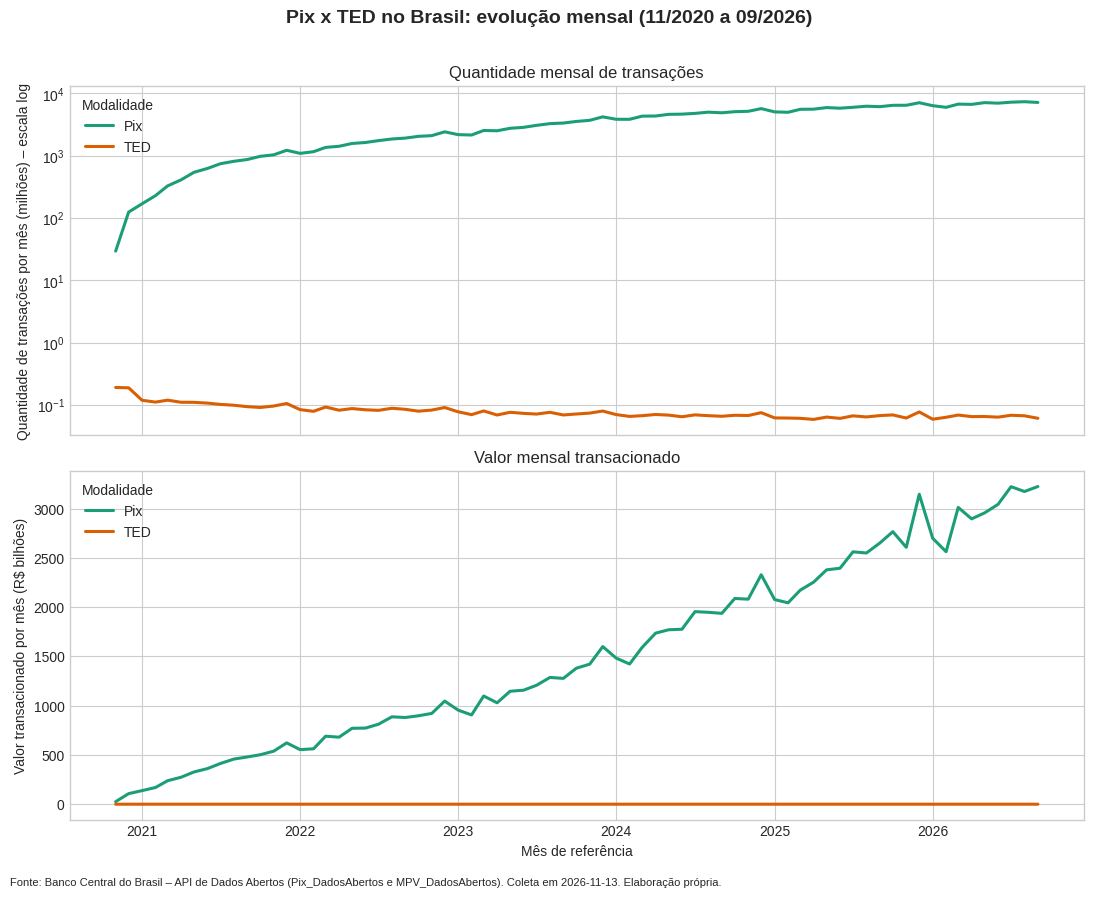

In [54]:
LOG_QTD = True   # ⚠️ ajuste para False se, depois de ver o gráfico, preferir escala linear

try:
    plt.style.use("seaborn-v0_8-whitegrid")
except OSError:
    plt.style.use("ggplot")

x = final["mes_referencia"]
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 9), sharex=True)

ax1.plot(x, final["pix_quantidade_mi"], color="#1b9e77", lw=2.2, label="Pix")
ax1.plot(x, final["ted_quantidade_mi"], color="#d95f02", lw=2.2, label="TED")
ax1.set_ylabel("Quantidade de transações por mês (milhões)" + (" – escala log" if LOG_QTD else ""))
ax1.set_title("Quantidade mensal de transações")
if LOG_QTD:
    ax1.set_yscale("log")
ax1.legend(title="Modalidade", loc="upper left")

ax2.plot(x, final["pix_valor_bi"], color="#1b9e77", lw=2.2, label="Pix")
ax2.plot(x, final["ted_valor_bi"], color="#d95f02", lw=2.2, label="TED")
ax2.set_ylabel("Valor transacionado por mês (R$ bilhões)")
ax2.set_title("Valor mensal transacionado")
ax2.set_xlabel("Mês de referência")
ax2.legend(title="Modalidade", loc="upper left")
ax2.xaxis.set_major_locator(mdates.YearLocator())
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax2.xaxis.set_minor_locator(mdates.MonthLocator(bymonth=(1, 4, 7, 10)))

fig.suptitle("Pix x TED no Brasil: evolução mensal (" +
             f"{x.min():%m/%Y} a {x.max():%m/%Y})", fontsize=14, fontweight="bold")
fig.text(0.01, 0.005,
         "Fonte: Banco Central do Brasil – API de Dados Abertos (Pix_DadosAbertos e MPV_DadosAbertos). "
         f"Coleta em {DATA_COLETA[:10]}. Elaboração própria.", fontsize=8, ha="left", va="bottom")
fig.tight_layout(rect=(0, 0.02, 1, 0.97))
fig.savefig(OUT_DIR / "grafico_pix_ted.png", dpi=200, bbox_inches="tight")
plt.show()

### Interpretação

Roteiro do que comentar, **usando os números da sua tabela final**:

1. **Quantidade:** quando o Pix ultrapassa a TED? Qual a razão Pix/TED no último mês?
2. **Valor:** o Pix alcança a TED em valor? Compare `pix_valor_bi` e `ted_valor_bi` no fim da série.
3. **Ticket médio:** compare `pix_ticket_medio_rs` e `ted_ticket_medio_rs` – o que isso sugere sobre o uso típico de cada modalidade (varejo/pessoas vs. operações de maior valor)?
4. **Tendência:** a TED cai em termos absolutos ou só perde participação relativa?

### Resposta:

1. Quantidade. No lançamento (11/2020), a TED ainda era muito maior: cerca de 192 milhões de transações contra 30 milhões do Pix. O Pix ultrapassa a TED em janeiro de 2021 (170 milhões contra 119 milhões) e abre uma distância crescente. Em setembro de 2026 o Pix registra cerca de 7,17 bilhões de transações e a TED cerca de 61 milhões, uma razão Pix/TED de aproximadamente 117 vezes.

2. Valor. Aqui o resultado é outro. Em setembro de 2026 o Pix movimenta cerca de R$ 3,23 trilhões e a TED cerca de R$ 4,13 trilhões, uma razão Pix/TED de 0,78. Nas linhas que vi, o Pix se aproxima da TED, mas não a ultrapassa. Para afirmar que “nunca ultrapassou” no período todo, confira a saída completa da célula dos 4 pontos.

3. Ticket médio. A diferença é grande e vai em sentidos opostos. O Pix caiu de cerca de R$ 876 (11/2020) para cerca de R$ 450 (09/2026). A TED subiu de cerca de R$ 13 mil para cerca de R$ 67 mil. Em setembro de 2026, o ticket da TED é cerca de 150 vezes o do Pix. Isso sugere que o Pix passou a ser usado para pagamentos pequenos e frequentes, enquanto a TED se concentrou em operações de alto valor. É uma inferência dos números, não uma prova.

4. Tendência da TED. A TED caiu em termos absolutos na quantidade: de cerca de 192 milhões (pico em 11/2020) para cerca de 61 milhões, uma queda de aproximadamente 68%. Já o valor nominal subiu cerca de 61%, de R$ 2,57 trilhões para R$ 4,13 trilhões. Sua participação na quantidade somada (TED + Pix) caiu de cerca de 87% para cerca de 0,9%. Ou seja, ela perdeu volume e participação, mas concentrou valor.

### Limitações da comparação (ponto de partida)

- **Fontes e metodologias diferentes:** Pix e TED vêm de recursos distintos do BC, com regras de coleta próprias.
- **Cobertura do Pix:** a base de estatísticas não inclui Pix liquidados nos livros do próprio participante (não enviados ao SPI), segundo a descrição do BC. Isso pode subestimar o Pix.
- **TED:** conferir se o recorte inclui apenas TED (e não DOC/TEC) e o que a fonte (CIP-SITRAF/STR) cobre.
- **Valores nominais:** sem correção pela inflação; o crescimento em R$ mistura aumento real e efeito de preços.
- **Não é substituição pura:** o Pix criou novos usos (pagamentos pequenos do dia a dia) que nunca existiram na TED; queda da TED não é só migração para o Pix.
- **Efeito de escala:** a escala log da quantidade facilita ver as duas séries, mas exagera visualmente a TED.

## Etapa 9 – Saídas (entregáveis)

In [55]:
final_out = final.copy()
final_out["mes_referencia"] = final_out["mes_referencia"].dt.strftime("%Y-%m-%d")
final_out.to_csv(OUT_DIR / "tabela_final_pix_ted.csv", index=False, encoding="utf-8")   # texto, não planilha

registro_aquisicao.to_csv(OUT_DIR / "registro_aquisicao.csv", index=False, encoding="utf-8")
registro_variaveis.to_csv(OUT_DIR / "registro_variaveis.csv", index=False, encoding="utf-8")
classificacao_variaveis.to_csv(OUT_DIR / "classificacao_variaveis.csv", index=False, encoding="utf-8")
pd.concat([diag_pix_antes, diag_ted_antes]).to_csv(OUT_DIR / "diagnostico_antes.csv", index=False, encoding="utf-8")
pd.concat([diag_pix_depois, diag_ted_depois, diag_final]).to_csv(OUT_DIR / "diagnostico_depois.csv", index=False, encoding="utf-8")
pd.concat([comp_pix, comp_ted]).to_csv(OUT_DIR / "comparativo_antes_depois.csv", index=False, encoding="utf-8")
log_tratamentos.to_csv(OUT_DIR / "log_tratamentos.csv", index=False, encoding="utf-8")

zip_path = BASE_DIR / "entregaveis_n1.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for p in list(OUT_DIR.glob("*")) + list(RAW_DIR.glob("*")):
        z.write(p, arcname=f"{p.parent.name}/{p.name}")
print("Arquivos gerados:")
for p in sorted(OUT_DIR.glob("*")):
    print(" -", p)
print("\nPacote completo:", zip_path)

try:
    from google.colab import files
    files.download(str(zip_path))
except Exception:
    pass

Arquivos gerados:
 - /content/saidas/classificacao_variaveis.csv
 - /content/saidas/comparativo_antes_depois.csv
 - /content/saidas/diagnostico_antes.csv
 - /content/saidas/diagnostico_depois.csv
 - /content/saidas/grafico_pix_ted.png
 - /content/saidas/log_tratamentos.csv
 - /content/saidas/registro_aquisicao.csv
 - /content/saidas/registro_variaveis.csv
 - /content/saidas/tabela_final_pix_ted.csv

Pacote completo: /content/entregaveis_n1.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Referências

- BANCO CENTRAL DO BRASIL. *Portal de Dados Abertos – Pix (API EstatisticasTransacoesPix)*. https://dadosabertos.bcb.gov.br/dataset/pix
- BANCO CENTRAL DO BRASIL. *Portal de Dados Abertos – Estatísticas de Meios de Pagamentos (recurso MeiosdePagamentosMensalDA)*. https://dadosabertos.bcb.gov.br/dataset/estatisticas-meios-pagamentos
- Complete com: documentação do pandas, matplotlib e requests, material da disciplina e quaisquer outras fontes que você usar (com data de acesso).